# Figures of the paper

Every figure of `Paper/Journal/main.tex`, in the style of the first (rejected) version of the paper: LaTeX text, bars
with black edges and one hatch per series, boxed legends, dashed baselines (`paper_style.py`).

**Readable without colour.** Every series has a channel that is not colour: a hatch for bars, a marker and a dash
pattern for lines, a marker shape for points, and names on the axes or in a legend. The colours (a validated
colour-blind-safe palette for the models, a red–grey–blue scale for the NewsGuard levels) only add to them. The last
cell renders every figure in greyscale to check this.

**Data** (outside git, `Dataset/tentativi/20_FromScratch/`): `outlets.csv`, `split.csv`, the step-7 predictions,
`paper_main_table.csv`, `paper_curves.csv` (pipeline, `Code/Pipeline`), `paper_figures/` (written on the server by
`dataset_construction.py`), `paper_figures/analyses.json` (written by `analyses.py`, called here). Only aggregates are plotted; outlets are
never named. Each figure is saved as `<name>.pdf` next to this notebook, the file that `main.tex` includes.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

HERE = Path.cwd()
sys.path.insert(0, str(HERE))
import analyses as AN
import paper_style as S

DATA = HERE.parents[2] / "Dataset" / "tentativi" / "20_FromScratch"
FIG = DATA / "paper_figures"
S.set_style()
print("LaTeX text:", S._USETEX)

outlets = pd.read_csv(DATA / "outlets.csv", index_col="domain")
outlets["fold"] = pd.read_csv(DATA / "split.csv", index_col="domain").fold
main = pd.read_csv(DATA / "paper_main_table.csv")
curves = pd.read_csv(DATA / "paper_curves.csv")
A = AN.main()                                   # the further analyses (also writes analyses.json)
_, art = AN.load()
pred = {m: art[m].groupby("domain").prediction.mean().reindex(outlets.index) for m in S.MODELS}
notext = pd.Series({d: outlets.score[outlets.fold != f].mean() for d, f in outlets.fold.items()})
NOTEXT = {"MAE": float((notext - outlets.score).abs().mean()),
          "within 20": float(((notext - outlets.score).abs() <= 20).mean() * 100)}
print("no text:", {k: round(v, 1) for k, v in NOTEXT.items()})

LaTeX text: True


{
 "article_level": {
  "TF-IDF": {
   "spearman": 0.42903017586826786,
   "mae": 20.4450266648305,
   "within_20": 56.57812255132424
  },
  "Qwen3-8B": {
   "spearman": 0.5254701475091381,
   "mae": 19.443666540899937,
   "within_20": 59.2501175364363
  },
  "Mistral-24B": {
   "spearman": 0.6143175586664179,
   "mae": 17.849106833399937,
   "within_20": 63.52452593637361
  },
  "ModernBERT": {
   "spearman": 0.4581667785971945,
   "mae": 20.35160567666377,
   "within_20": 58.00423131170663
  }
 },
 "outlet_level": {
  "TF-IDF": {
   "spearman": 0.6743890219615788,
   "mae": 17.82465736150067,
   "range": [
    37.280371807976266,
    98.27985137620388
   ]
  },
  "Qwen3-8B": {
   "spearman": 0.7111604066826399,
   "mae": 16.310593660014973,
   "range": [
    38.33132342929293,
    99.01631678947368
   ]
  },
  "Mistral-24B": {
   "spearman": 0.7348485353287721,
   "mae": 15.793377406966398,
   "range": [
    37.26838060869565,
    95.99601843820224
   ]
  },
  "ModernBERT": {
   "spe

no text: {'MAE': 22.6, 'within 20': 50.9}


## 1. The dataset (`dataset.pdf`)
(a) Outlets per political orientation and NewsGuard level, as the leaning figure of the first version; (b) articles
per outlet; (c) score of the outlets in each fold.

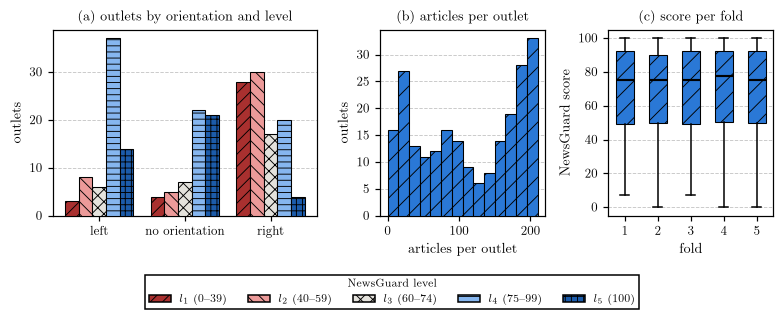

In [2]:
fig, (a, b, c) = plt.subplots(1, 3, figsize=(7.2, 2.5), gridspec_kw={"width_ratios": [1.6, 1, 1]})
sides = [("Left", "left"), ("none", "no orientation"), ("Right", "right")]
ct = pd.crosstab(outlets.orientation, outlets.level).reindex(index=[s for s, _ in sides], columns=S.LEVELS, fill_value=0)
w = 0.16
for i, lv in enumerate(S.LEVELS):
    a.bar(np.arange(3) + (i - 2) * w, ct[lv], w, color=S.LEVEL_COLORS[i], hatch=S.LEVEL_HATCHES[i], edgecolor="black",
          linewidth=0.7, zorder=3)
a.set_xticks(range(3), [lab for _, lab in sides]); a.set_ylabel("outlets")
a.set_title("(a) outlets by orientation and level")
fig.legend(handles=S.level_handles(), title="NewsGuard level", loc="lower center", ncol=5, fontsize=7, title_fontsize=7,
           bbox_to_anchor=(0.5, -0.16))
b.hist(outlets.articles, bins=np.arange(0, 211, 15), color=S.SLOTS[0], hatch="//", edgecolor="black", linewidth=0.7, zorder=3)
b.set_xlabel("articles per outlet"); b.set_ylabel("outlets"); b.set_title("(b) articles per outlet")
bp = c.boxplot([outlets.score[outlets.fold == f] for f in range(1, 6)], widths=0.55, patch_artist=True,
               medianprops={"color": "black", "linewidth": 1.4})
for box in bp["boxes"]:
    box.set(facecolor=S.SLOTS[0], hatch="//", edgecolor="black", linewidth=0.7)
c.set_xlabel("fold"); c.set_ylabel("NewsGuard score"); c.set_title("(c) score per fold")
fig.tight_layout(); S.save(fig, "dataset"); plt.show()

## 2. Sister outlets through the cleaning (`groups.pdf`)
Outlets after each step, split into one outlet per ownership group and the other outlets of the same group.

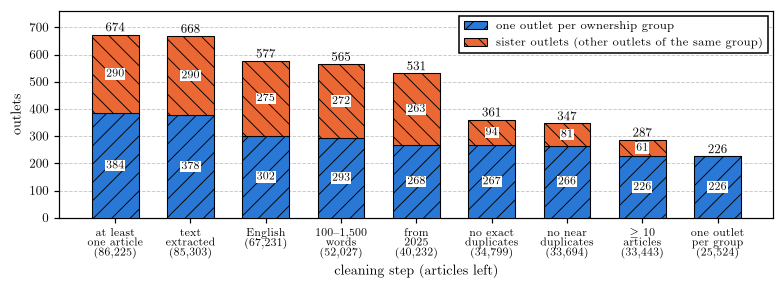

In [3]:
s = pd.read_csv(FIG / "steps.csv")
s = s[s.step != "sent to the scraper"].reset_index(drop=True)
names = {"at least one article": "at least\none article", "text extracted": "text\nextracted", "English": "English",
         "100-1,500 words": S.tex("100--1,500\nwords"), "from 2025": "from\n2025", "no exact duplicates": "no exact\nduplicates",
         "no near duplicates": "no near\nduplicates", ">= 10 articles": S.tex("$\\geq$ 10\narticles"),
         "one outlet per group": "one outlet\nper group"}
x = np.arange(len(s))
fig, ax = plt.subplots(figsize=(7.2, 2.7))
ax.bar(x, s.groups, 0.62, color=S.SLOTS[0], hatch="//", edgecolor="black", linewidth=0.7, zorder=3,
       label="one outlet per ownership group")
ax.bar(x, s.sister_outlets, 0.62, bottom=s.groups, color=S.SLOTS[1], hatch="\\\\", edgecolor="black", linewidth=0.7,
       zorder=3, label="sister outlets (other outlets of the same group)")
for i, r in s.iterrows():
    ax.text(i, r.outlets + 12, f"{r.outlets}", ha="center", fontsize=8, fontweight="bold")
    if r.sister_outlets:
        ax.text(i, r.groups + r.sister_outlets / 2, f"{r.sister_outlets}", ha="center", va="center", fontsize=7,
                bbox=dict(facecolor="white", edgecolor="none", pad=0.6))
    ax.text(i, r.groups / 2, f"{r.groups}", ha="center", va="center", fontsize=7,
            bbox=dict(facecolor="white", edgecolor="none", pad=0.6))
ax.set_xticks(x, [f"{names.get(n, n)}\n({r:,.0f})" for n, r in zip(s.step, s.articles)], fontsize=7)
ax.set_xlabel("cleaning step (articles left)"); ax.set_ylabel("outlets"); ax.set_ylim(0, s.outlets.max() * 1.13)
ax.legend(loc="upper right", fontsize=7.5)
fig.tight_layout(); S.save(fig, "groups"); plt.show()

## 3. Ownership groups and shared text (`network.pdf`)
(a) Outlets linked by shared articles before deduplication: the three largest ownership groups on the map have their
own marker shape (and colour); hollow markers are outlets not in the final dataset. (b) After deduplication, the
similarity of each outlet with a sister to its nearest sister and to the nearest outlet of another group.

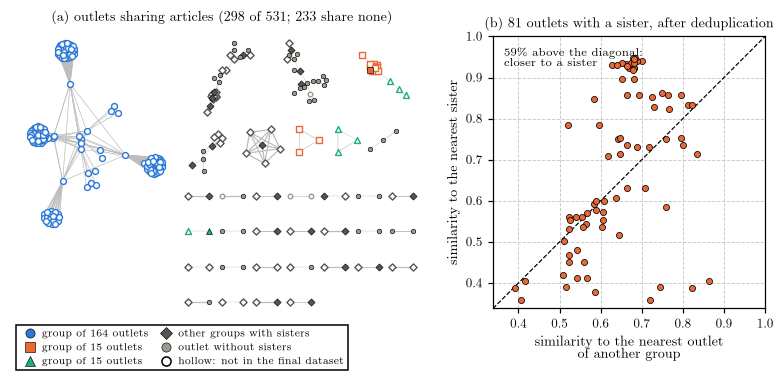

In [4]:
nodes, edges = pd.read_csv(FIG / "nodes.csv"), pd.read_csv(FIG / "edges.csv")
sim = pd.read_csv(FIG / "similarity.csv")
fig, (a, b) = plt.subplots(1, 2, figsize=(7.2, 3.5), gridspec_kw={"width_ratios": [1.55, 1]})
pos = S.packed_layout(edges)
shown = nodes[nodes.node.isin(pos)].set_index("node")
shown["x"] = [pos[v][0] for v in shown.index]; shown["y"] = [pos[v][1] for v in shown.index]
for e in edges.itertuples():
    if e.a in shown.index and e.b in shown.index:
        pa, pb = shown.loc[e.a], shown.loc[e.b]
        a.plot([pa.x, pb.x], [pa.y, pb.y], color="#bdbdbd", lw=0.25 + 0.25 * np.log10(e.shared), zorder=1)
big = list(shown[shown.group_size > 1].group.value_counts().index[:3])
kinds = [(f"group of {nodes.group_size[nodes.group == g].iloc[0]} outlets", shown.group == g, S.SLOTS[i], m, 15)
         for i, (g, m) in enumerate(zip(big, ["o", "s", "^"]))]
kinds += [("other groups with sisters", ~shown.group.isin(big) & (shown.group_size > 1), "#55544f", "D", 11),
          ("outlet without sisters", shown.group_size == 1, "#9a998f", "o", 9)]
handles = []
for label, mask, colour, marker, size in kinds:
    for kept in (True, False):
        d = shown[mask & (shown.kept == kept)]
        if kept:
            a.scatter(d.x, d.y, s=size, marker=marker, color=colour, edgecolors="black", linewidths=0.4, zorder=3)
        else:
            a.scatter(d.x, d.y, s=size, marker=marker, facecolors="white", edgecolors=colour, linewidths=0.9, zorder=2)
    handles.append(Line2D([], [], marker=marker, ls="", color=colour, markeredgecolor="black", markeredgewidth=0.4,
                          label=label))
handles.append(Line2D([], [], marker="o", ls="", markerfacecolor="white", markeredgecolor="black",
                      label="hollow: not in the final dataset"))
a.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.0, -0.02), ncol=2, fontsize=6.5, handletextpad=0.2,
         columnspacing=0.8)
a.set_xticks([]); a.set_yticks([]); a.grid(False); a.set_aspect("equal")
for sp in a.spines.values():
    sp.set_visible(False)
a.set_title(f"(a) outlets sharing articles ({len(shown)} of {len(nodes)}; {len(nodes) - len(shown)} share none)")
w = sim[sim.has_sister]
lim = (min(w.nearest_other.min(), w.nearest_sister.min()) - 0.02, 1.0)
b.plot(lim, lim, color="black", lw=0.8, ls="--", zorder=1)
b.scatter(w.nearest_other, w.nearest_sister, s=16, marker="o", color=S.SLOTS[1], edgecolors="black", linewidths=0.5, zorder=2)
b.text(0.04, 0.96, S.tex(f"{(w.nearest_sister > w.nearest_other).mean():.0%} above the diagonal:\ncloser to a sister"),
       transform=b.transAxes, va="top", fontsize=7.5)
b.set_xlim(lim); b.set_ylim(lim); b.set_aspect("equal"); b.grid(True, axis="both")
b.set_xlabel("similarity to the nearest outlet\nof another group"); b.set_ylabel("similarity to the nearest sister")
b.set_title(f"(b) {len(w)} outlets with a sister, after deduplication")
fig.tight_layout(); S.save(fig, "network"); plt.show()

## 4. The anonymization (`anonymization.pdf`)
(a) Articles with at least one replacement of each kind; (b) articles that still contain the name of their own
outlet, after each pass; (c) replacements per 1,000 words by NewsGuard level, stacked by kind.

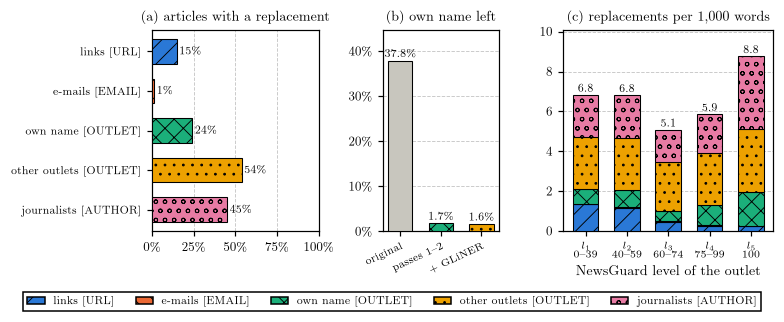

In [5]:
t = pd.read_csv(FIG / "anonymization.csv")
kinds = {"url": "links [URL]", "email": "e-mails [EMAIL]", "own_name": "own name [OUTLET]",
         "gliner_outlet": "other outlets [OUTLET]", "gliner_journalist": "journalists [AUTHOR]"}
fig, (a, b, c) = plt.subplots(1, 3, figsize=(7.2, 2.7), gridspec_kw={"width_ratios": [1.15, 0.8, 1.45]})
share = [(t[k] > 0).mean() for k in kinds]
y = np.arange(len(kinds))[::-1]
for yy, v, colour, hatch in zip(y, share, S.SLOTS, S.HATCHES):
    a.barh(yy, v, 0.62, color=colour, hatch=hatch, edgecolor="black", linewidth=0.7, zorder=3)
    a.text(v + 0.015, yy, S.tex(f"{v:.0%}"), va="center", fontsize=7)
a.set_yticks(y, list(kinds.values()), fontsize=7); a.set_xlim(0, 1); a.grid(True, axis="x"); a.grid(False, axis="y")
a.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: S.tex(f"{v:.0%}")))
a.set_title("(a) articles with a replacement")
stages = [("original", "own_name_left_raw"), ("passes 1--2", "own_name_left_rules"), ("+ GLiNER", "own_name_left_final")]
v = [t[col].mean() for _, col in stages]
# original: plain grey; passes 1-2: as the own-name rule in (a); + GLiNER: as the GLiNER kinds in (a)
for i, (vv, hatch, colour) in enumerate(zip(v, ["", S.HATCHES[2], S.HATCHES[3]], ["#c8c6be", S.SLOTS[2], S.SLOTS[3]])):
    b.bar(i, vv, 0.6, color=colour, hatch=hatch, edgecolor="black", linewidth=0.7, zorder=3)
    b.text(i, vv + 0.008, S.tex(f"{vv:.1%}"), ha="center", fontsize=7)
b.set_xticks(range(3), [S.tex(s) for s, _ in stages], fontsize=6.5, rotation=25, ha="right", rotation_mode="anchor")
b.set_ylim(0, max(v) * 1.18)
b.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: S.tex(f"{v:.0%}")))
b.set_title("(b) own name left")
per = t[list(kinds)].div(t.words, axis=0) * 1000
m = per.groupby(t.level).mean().reindex(S.LEVELS)
bottom = np.zeros(len(m))
for k, colour, hatch in zip(kinds, S.SLOTS, S.HATCHES):
    c.bar(range(5), m[k], 0.62, bottom=bottom, color=colour, hatch=hatch, edgecolor="black", linewidth=0.7, zorder=3)
    bottom += m[k].to_numpy()
for i, vv in enumerate(bottom):
    c.text(i, vv + 0.15, f"{vv:.1f}", ha="center", fontsize=7)
c.set_xticks(range(5), [S.tex(f"$l_{i + 1}$\n{b_}") for i, b_ in enumerate(S.LEVEL_BANDS)], fontsize=6.5)
c.set_ylim(0, bottom.max() * 1.15); c.set_xlabel("NewsGuard level of the outlet")
c.set_title("(c) replacements per 1,000 words")
fig.legend(handles=[Patch(facecolor=col, hatch=h, edgecolor="black", label=lab) for col, h, lab in zip(S.SLOTS, S.HATCHES, kinds.values())],
           loc="lower center", ncol=5, fontsize=7, bbox_to_anchor=(0.5, -0.08), handlelength=1.6)
fig.tight_layout(); S.save(fig, "anonymization"); plt.show()

## 5. Main results (`results.pdf`)
Per outlet, all articles: the measures of the ranking and the share within 20 points (a) and the error (b), with 95%
bootstrap intervals; dashed lines are the baselines, as in the publisher-level figure of the first version. (c) The
effect of aggregation: Spearman per article (hollow) and per outlet (filled).

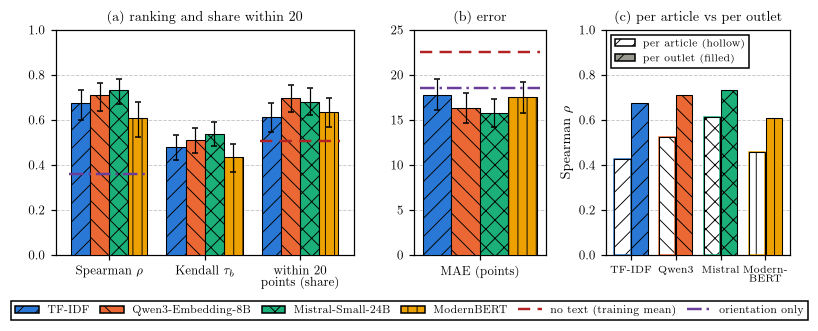

In [6]:
val = main.pivot(index="model", columns="measure", values="value")
low = main.pivot(index="model", columns="measure", values="low"); high = main.pivot(index="model", columns="measure", values="high")
fig, (a, b, c) = plt.subplots(1, 3, figsize=(7.2, 2.8), gridspec_kw={"width_ratios": [1.7, 0.75, 1.05]})
measures = [("Spearman", "Spearman $\\rho$", 1), ("Kendall", "Kendall $\\tau_b$", 1), ("within 20", "within 20\npoints (share)", 100)]
groups = [m for m, _, _ in measures]
values = {mo: {g: val.loc[mo, g] / d for g, _, d in measures} for mo in S.MODELS}
errors = {mo: {g: (low.loc[mo, g] / d, high.loc[mo, g] / d) for g, _, d in measures} for mo in S.MODELS}
x = S.grouped_bars(a, groups, S.MODELS, values, {mo: S.model_bar(mo) for mo in S.MODELS}, errors=errors)
a.set_xticklabels([S.tex(lab) for _, lab, _ in measures]); a.set_ylim(0, 1); a.set_title("(a) ranking and share within 20")
S.baseline(a, x[0] - 0.42, x[0] + 0.42, A["orientation_only"]["spearman"], "violet")
S.baseline(a, x[2] - 0.42, x[2] + 0.42, NOTEXT["within 20"] / 100, "red")
values = {mo: {"MAE": val.loc[mo, "MAE"]} for mo in S.MODELS}
errors = {mo: {"MAE": (low.loc[mo, "MAE"], high.loc[mo, "MAE"])} for mo in S.MODELS}
x = S.grouped_bars(b, ["MAE"], S.MODELS, values, {mo: S.model_bar(mo) for mo in S.MODELS}, errors=errors)
b.set_xticklabels(["MAE (points)"]); b.set_ylim(0, 25); b.set_title("(b) error")
S.baseline(b, -0.42, 0.42, NOTEXT["MAE"], "red"); S.baseline(b, -0.42, 0.42, A["orientation_only"]["mae"], "violet")
xs = np.arange(len(S.MODELS))
for i, mo in enumerate(S.MODELS):
    c.bar(i - 0.19, A["article_level"][mo]["spearman"], 0.36, facecolor="white", hatch=S.MODEL_HATCHES[mo],
          edgecolor=S.MODEL_COLORS[mo], linewidth=1.0, zorder=3)
    c.bar(i - 0.19, A["article_level"][mo]["spearman"], 0.36, facecolor="none", edgecolor="black", linewidth=0.7, zorder=4)
    c.bar(i + 0.19, A["outlet_level"][mo]["spearman"], 0.36, zorder=3, **S.model_bar(mo))
c.set_xticks(xs, ["TF-IDF", "Qwen3", "Mistral", "Modern-\nBERT"], fontsize=6.5)
c.set_ylim(0, 1); c.set_ylabel("Spearman $\\rho$"); c.set_title("(c) per article vs per outlet")
c.legend(handles=[Patch(facecolor="white", edgecolor="black", hatch="//", label="per article (hollow)"),
                  Patch(facecolor="#9a998f", edgecolor="black", hatch="//", label="per outlet (filled)")],
         loc="upper left", fontsize=6.5)
fig.legend(handles=S.model_handles() + [S.baseline_handle("red", "no text (training mean)"),
                                        S.baseline_handle("violet", "orientation only")],
           loc="lower center", ncol=6, fontsize=7, bbox_to_anchor=(0.5, -0.07), handlelength=2.2, columnspacing=1.0)
fig.tight_layout(); S.save(fig, "results"); plt.show()

## 6. How many articles are needed (`curves.pdf`)
Spearman and MAE per outlet as a function of the articles read per outlet (mean of 20 random draws per outlet).

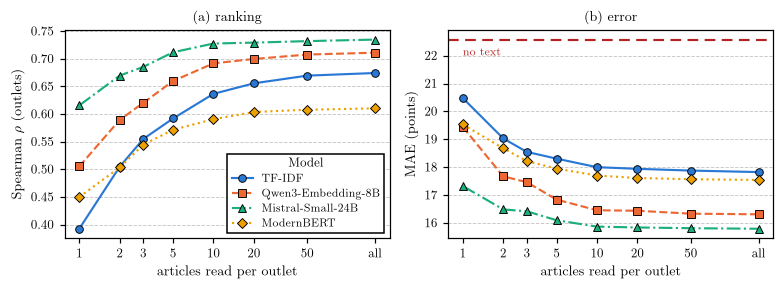

In [7]:
K = ["1", "2", "3", "5", "10", "20", "50", "all"]; X = [1, 2, 3, 5, 10, 20, 50, 160]
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.7))
for ax, measure in zip(axes, ["Spearman", "MAE"]):
    for mo in S.MODELS:
        d = curves[(curves.model == mo) & (curves.measure == measure)].set_index("k").value.reindex(K)
        ax.plot(X, d.to_numpy(), label=S.MODEL_NAMES[mo], zorder=3, **S.model_line(mo))
    ax.set_xscale("log"); ax.set_xticks(X, K); ax.minorticks_off(); ax.set_xlabel("articles read per outlet")
axes[1].axhline(NOTEXT["MAE"], **{"color": S.BASELINE_RED, "linestyle": (0, (5, 3)), "linewidth": 1.4})
axes[1].text(1, NOTEXT["MAE"] - 0.3, "no text", va="top", fontsize=7, color=S.BASELINE_RED)
axes[0].set_ylabel("Spearman $\\rho$ (outlets)"); axes[1].set_ylabel("MAE (points)")
axes[0].set_title("(a) ranking"); axes[1].set_title("(b) error")
axes[0].legend(title="Model", loc="lower right", fontsize=7)
fig.tight_layout(); S.save(fig, "curves"); plt.show()

## 7. Predicted against true score (`scatter.pdf`)
One point per outlet; the NewsGuard level is given by the marker shape and by the colour.

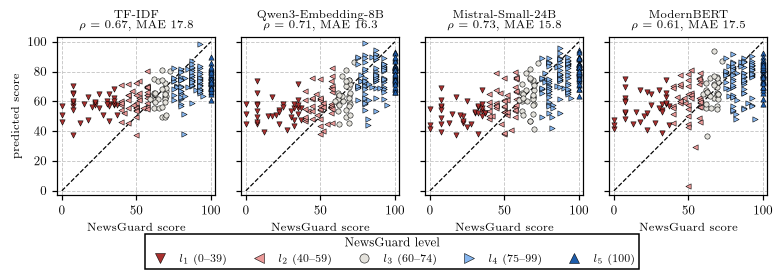

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(7.2, 2.25), sharex=True, sharey=True)
for ax, mo in zip(axes, S.MODELS):
    ax.plot([0, 100], [0, 100], color="black", lw=0.8, ls="--", zorder=1)
    for i, lv in enumerate(S.LEVELS):
        d = outlets.level == lv
        ax.scatter(outlets.score[d], pred[mo][d], s=12, marker=S.LEVEL_MARKERS[i], color=S.LEVEL_COLORS[i],
                   edgecolors="black", linewidths=0.35, zorder=2)
    r = A["outlet_level"][mo]
    ax.set_title(S.tex(f"{S.MODEL_NAMES[mo]}\n$\\rho$ = {r['spearman']:.2f}, MAE {r['mae']:.1f}"), fontsize=7.5)
    ax.set_xlim(-3, 103); ax.set_ylim(-3, 103); ax.set_aspect("equal"); ax.grid(True, axis="both")
    ax.set_xlabel("NewsGuard score", fontsize=7.5)
axes[0].set_ylabel("predicted score", fontsize=7.5)
fig.legend(handles=[Line2D([], [], marker=S.LEVEL_MARKERS[i], ls="", color=S.LEVEL_COLORS[i], markeredgecolor="black",
                           markeredgewidth=0.35, label=S.tex(f"$l_{i + 1}$ ({b_})")) for i, b_ in enumerate(S.LEVEL_BANDS)],
           title="NewsGuard level", loc="lower center", ncol=5, fontsize=7, bbox_to_anchor=(0.5, -0.12))
fig.tight_layout(); S.save(fig, "scatter"); plt.show()

## 8. Where the models err (`errors.pdf`)
(a) Mean signed error per NewsGuard level, as the mean-error-direction figures of the first version; (b) mean signed
error per orientation at equal NewsGuard score; (c) Spearman within the outlets of one orientation, with 95%
bootstrap intervals.

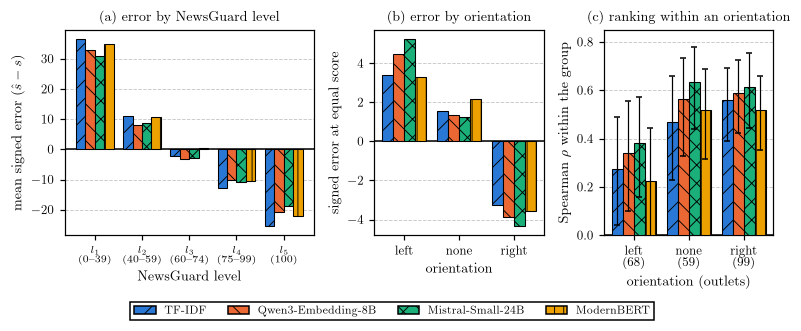

In [9]:
fig, (a, b, c) = plt.subplots(1, 3, figsize=(7.2, 2.8), gridspec_kw={"width_ratios": [1.4, 0.95, 0.95]})
styles = {mo: S.model_bar(mo) for mo in S.MODELS}
values = {mo: {lv: A["levels"][mo][lv]["signed"] for lv in S.LEVELS} for mo in S.MODELS}
S.grouped_bars(a, S.LEVELS, S.MODELS, values, styles, zero_line=True)
a.set_xticklabels([S.tex(f"$l_{i + 1}$\n({b_})") for i, b_ in enumerate(S.LEVEL_BANDS)], fontsize=6.5)
a.set_ylabel(S.tex("mean signed error $(\\hat{s} - s)$")); a.set_xlabel("NewsGuard level")
a.set_title("(a) error by NewsGuard level")
sides = [("Left", "left"), ("none", "none"), ("Right", "right")]
values = {mo: {s_: A["orientation"][mo]["signed_at_equal_score"][s_] for s_, _ in sides} for mo in S.MODELS}
S.grouped_bars(b, [s_ for s_, _ in sides], S.MODELS, values, styles, zero_line=True)
b.set_xticklabels([lab for _, lab in sides]); b.set_xlabel("orientation"); b.set_ylabel("signed error at equal score")
b.set_title("(b) error by orientation")
values = {mo: {s_: A["within_orientation"][mo][s_]["spearman"] for s_, _ in sides} for mo in S.MODELS}
errors = {mo: {s_: tuple(A["within_orientation"][mo][s_]["ci"]) for s_, _ in sides} for mo in S.MODELS}
S.grouped_bars(c, [s_ for s_, _ in sides], S.MODELS, values, styles, errors=errors, zero_line=True)
c.set_xticklabels([f"{lab}\n({A['within_orientation']['TF-IDF'][s_]['n']})" for s_, lab in sides])
c.set_xlabel("orientation (outlets)"); c.set_ylabel("Spearman $\\rho$ within the group"); c.set_ylim(0, 0.85)
c.set_title("(c) ranking within an orientation")
fig.legend(handles=S.model_handles(), title=None, loc="lower center", ncol=4, fontsize=7, bbox_to_anchor=(0.5, -0.07))
fig.tight_layout(); S.save(fig, "errors"); plt.show()

## Check: the figures without colour
Every figure rendered in greyscale: series must stay distinguishable by hatch, marker, dash pattern or label.

dataset


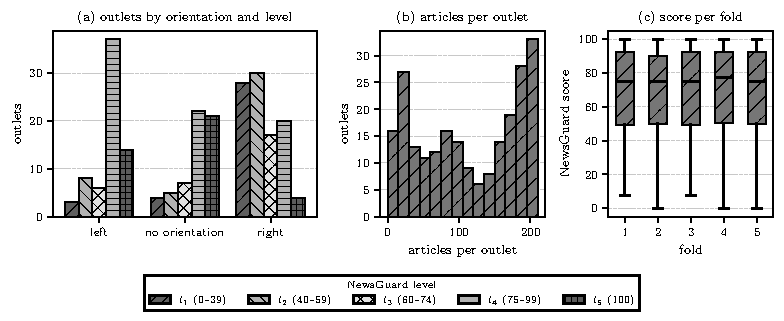

groups


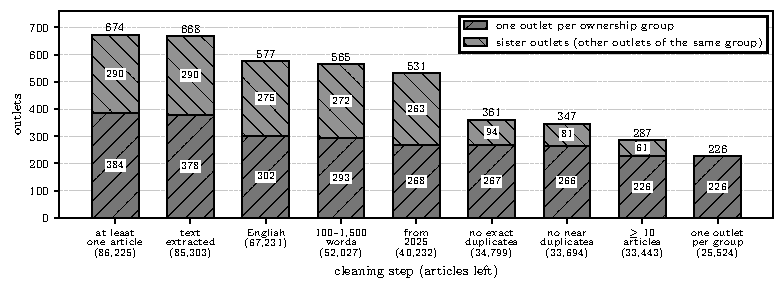

network


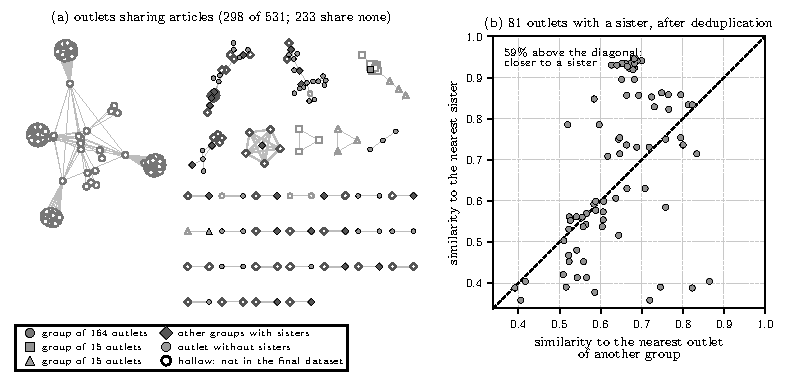

anonymization


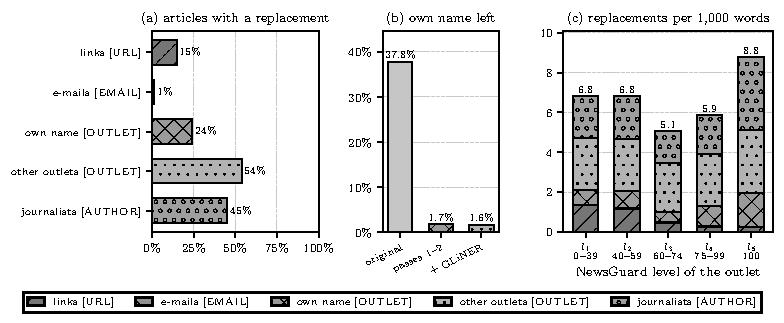

results


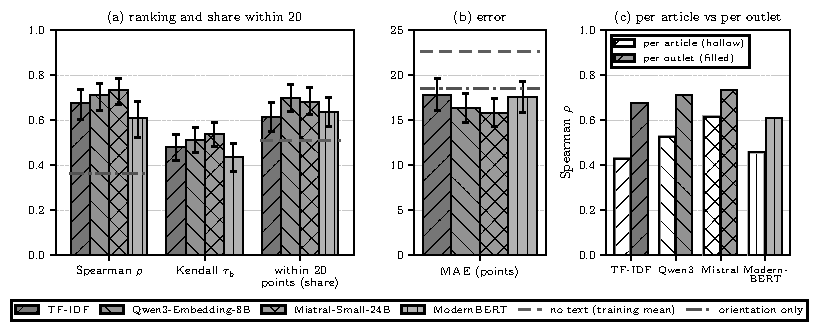

curves


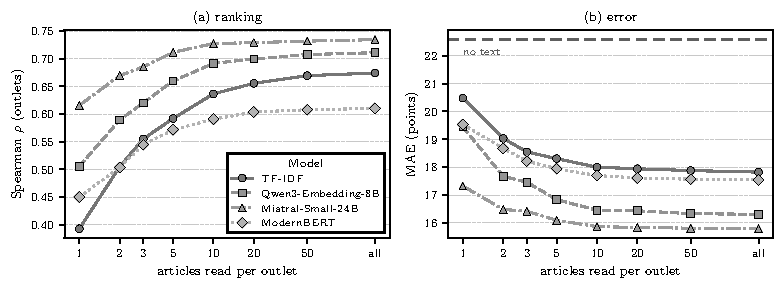

scatter


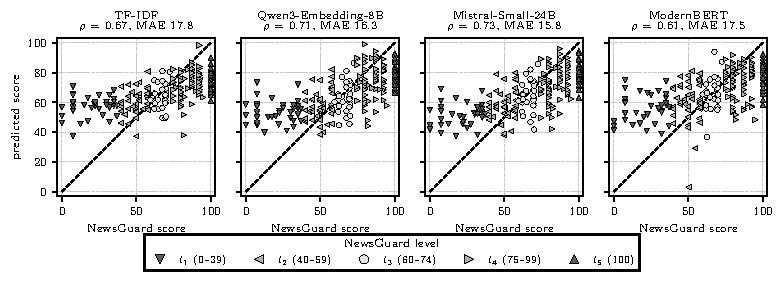

errors


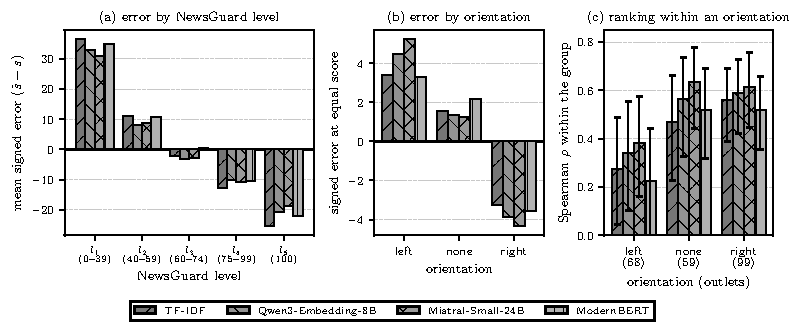

In [10]:
from IPython.display import Image, display
check = HERE / "_greyscale"; check.mkdir(exist_ok=True)
for name in ["dataset", "groups", "network", "anonymization", "results", "curves", "scatter", "errors"]:
    print(name); display(Image(filename=str(S.greyscale_check(HERE / f"{name}.pdf", check / f"{name}.png")), width=700))